# Exercise 1: PCA, ICA and Sparse Coding

**Note**: Please insert the names of all participating students:

1. Shawon,Mohammed Ibrahim
2.
3.
4.
5.

## Preamble
The following code downloads and imports all necessary files and modules into the virtual machine of Colab. Please make sure to execute it before solving this exercise.

In [21]:
import sys, os
if 'google.colab' in sys.modules:
  if os.getcwd() == '/content':
    !git clone 'https://github.com/inb-luebeck/cs5450.git'
    os.chdir('cs5450')

## Exercise 1.1: Applying unsupervised methods

In this exercise, we will apply three unsupervised methods, namely *Principal Component Analysis (PCA)*, *Independent Component Analysis (ICA)*, and *Sparse Coding (SC)* to image patches taken from handwriting digits and faces.

Since implementing [ICA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.FastICA.html) and [SC](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.SparseCoder.html) is rather complex, we will use already existing python packages.

We will build on the python starter code given below. You only need to write code at the places indicated by `TODO`.
The two given datasets are `mnist.npz` for handwritten digits and `olivetti.npz` for faces. Each dataset contains a multi-dimensional array `data` with the first index corresponding to the observations and the second index corresponding to the features (grayscale pixels). Both datasets contain square-shaped images.

Implement the missing parts below. When done correctly, your code should do the following:
1. Load the dataset with either handwritten images or faces.
2. Enforce mean-free observations by subtracting the mean from the data.
3. Randomly draw square-shaped image patches from the data.
4. Apply one of the three unsupervised methods (PCA, ICA, or SC).
5. Show the resulting set of new basis vectors (i.e., the components for PCA and ICA).
6. Reconstruct the original image patches with different subsets of basis vectors.

Note that for sparse coding, the basis vectors are not ordered according to some metric (*unlike which method?*). To quickly reconstruct an image with only $i$ non-zero values, you should use the coefficients and basis vectors corresponding to the $i$ highest absolute coefficients (see [numpy.argsort](https://numpy.org/doc/stable/reference/generated/numpy.argsort.html)).

In case you are struggeling with the task, here are some helpful tips and hints:
1. Useful functions: [`numpy.load`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.load.html), [`ndarray.astype`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.ndarray.astype.html), [`numpy.mean`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.mean.html), [`numpy.linalg.pinv`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.linalg.pinv.html), [`numpy.matmul`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.matmul.html), [`numpy.stack`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.stack.html), `random_patches`, `show_in_grid`, [`PCA`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [`FastICA`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.FastICA.html#sklearn.decomposition.FastICA), [`DictionaryLearning`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.DictionaryLearning.html#sklearn.decomposition.DictionaryLearning),[`numpy.argsort`](https://numpy.org/doc/stable/reference/generated/numpy.argsort.html)
2. **Complete the basis computation and reconstruction for PCA first.**
3. To obtain the coefficients $\vec{x}_{pca}$ and $\vec{x}_{ica}$, only matrix multiplication is needed. Use "sparse_encode" to obtain $\vec{x}_{sc}$
4. Since learning a sparse coding dictionary can take a long time, we provide a pre-computed basis at "data/sc_basis.npy" that you only need to load. **Note that the pre-computed basis only works with MNIST and a patch-size of 25!**
As a starting point you can use the following initial values:
- `dataset="mnist"`
- `n_patches=10000`
- `patch_size=25`
- `n_basis=100`

And for Sparse Coding also:
- `n_iterations=50`
- `n_jobs=-1` and
- `verbose=True`

Import and helper functions. Do not change!

In [22]:

import numpy as np
import math
import random
import matplotlib.pyplot as plt

from sklearn.decomposition import (
    PCA, FastICA, DictionaryLearning, sparse_encode
)

# Define variables
dataset = 'data/mnist.npz'
n_patches = 10000
patch_size = 25
n_basis = 100

# Choose 'pca', 'ica', or 'sc'
method = 'pca'

# Sparse Coding settings
n_iterations = 50
SC_LOAD_DICTIONARY = True

# Reproducibility
np.random.seed(42)
random.seed(42)


Your solution:

In [23]:

# TODO load dataset
loaded = np.load(dataset)
data = loaded['data']

# TODO convert data to floating point (double precision)
data = data.astype(np.float64)

# TODO get number of images and pixels
n_images, n_pixels = data.shape

# TODO get height and width
img_height = int(np.sqrt(n_pixels))
img_width = int(np.sqrt(n_pixels))

assert img_height * img_width == n_pixels
assert isinstance(img_height, int) and isinstance(img_width, int)

# TODO enforce mean-free data vectors
mean_free_data = data - np.mean(data, axis=0)

# TODO draw random patches
patches = random_patches(
    mean_free_data,
    img_height,
    img_width,
    n_patches,
    patch_size
)

print("Dataset shape:", data.shape)
print("Mean-free data shape:", mean_free_data.shape)
print("Patches shape:", patches.shape)


Dataset shape: (70000, 784)
Mean-free data shape: (70000, 784)
Patches shape: (10000, 625)


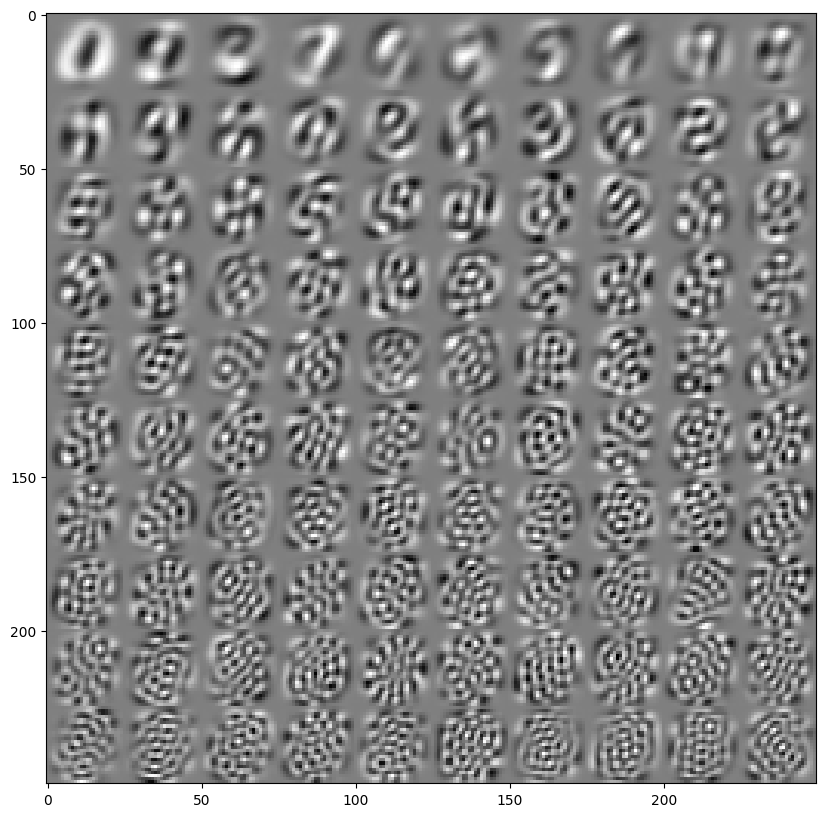

In [24]:

# TODO perform the chosen unsupervised method
if method == 'pca':

    model = PCA(n_components=n_basis)
    model.fit(patches)
    basis = model.components_

elif method == 'ica':

    model = FastICA(
        n_components=n_basis,
        random_state=42,
        max_iter=1000
    )
    model.fit(patches)
    basis = model.mixing_.T

elif method == 'sc':

    if SC_LOAD_DICTIONARY:
        basis = np.load('data/sc_basis.npy')
    else:
        model = DictionaryLearning(
            n_components=n_basis,
            max_iter=n_iterations,
            n_jobs=-1,
            verbose=True,
            random_state=42
        )
        model.fit(patches)
        basis = model.components_

else:
    raise ValueError("Unknown method")

# TODO show basis vectors
show_in_grid(basis[:n_basis], patch_size, patch_size)


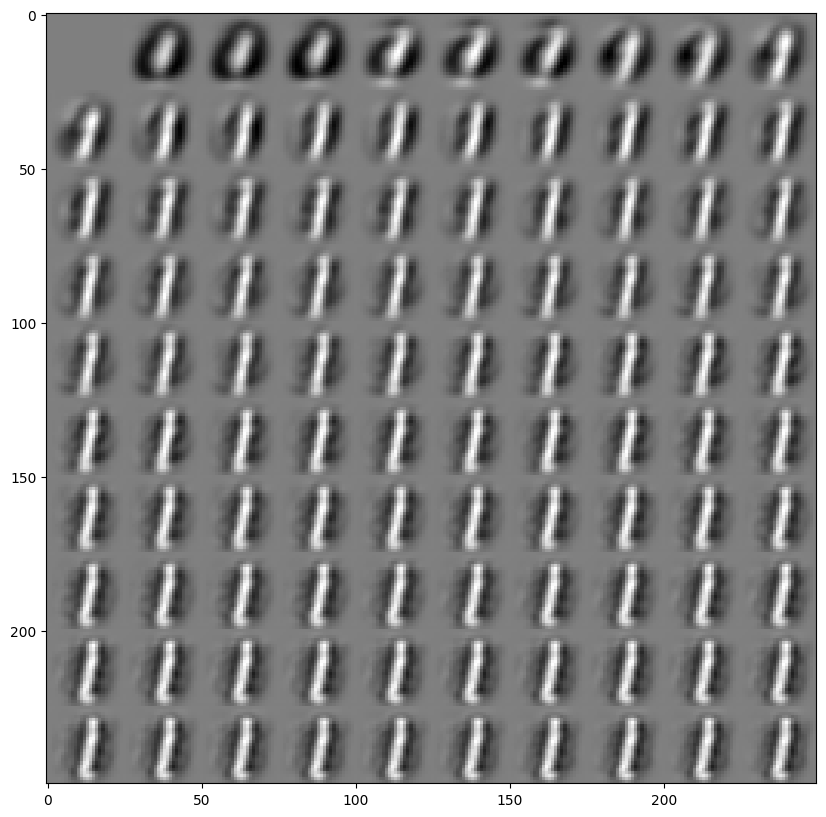

In [25]:

# RECONSTRUCTION

# TODO draw a random patch
random_patch = patches[random.randint(0, n_patches - 1)]

reconstructions = []

def sparse_coding_reconstruction(
    random_patch, basis, reconstructions, n_basis
):
    # Obtain sparse coefficients using the full dictionary
    coef = sparse_encode(
        random_patch.reshape(1, -1),
        dictionary=basis,
        algorithm='lasso_lars',
        alpha=1.0
    )[0]

    # Sort coefficients by absolute magnitude
    indices = np.argsort(np.abs(coef))[::-1]

    for i in range(n_basis):
        # Select i largest coefficients
        selected = indices[:i]

        # Compute reconstruction
        x_recon = coef[selected] @ basis[selected]

        reconstructions.append(x_recon)

    return reconstructions


def linear_reconstruction(
    random_patch, basis, reconstructions, n_basis
):
    for i in range(n_basis):
        # TODO only use the first i basis vectors
        selected_basis = basis[:i]

        if i == 0:
            x_recon = np.zeros_like(random_patch)
        else:
            # TODO compute inverse basis
            inverse_basis = np.linalg.pinv(selected_basis)

            # TODO compute coefficients
            coef = random_patch @ inverse_basis

            # TODO compute reconstruction
            x_recon = coef @ selected_basis

        reconstructions.append(x_recon)

    return reconstructions


if method == 'sc':
    reconstructions = sparse_coding_reconstruction(
        random_patch, basis, reconstructions, n_basis
    )
else:
    reconstructions = linear_reconstruction(
        random_patch, basis, reconstructions, n_basis
    )

reconstructions = np.stack(reconstructions)

# TODO show reconstructed patches
show_in_grid(reconstructions, patch_size, patch_size)


*Bonus*: Implement the missing parts in the bonus section. When done correctly, your code additionally should do the following:
1. Perform ZCA whitening, whereas $\vec{x}_{ZCAwhite}=U\vec{x}_{wht}$ (c.f. equation 1.3 in the lecture notes).
2. Visualize the whitened data.

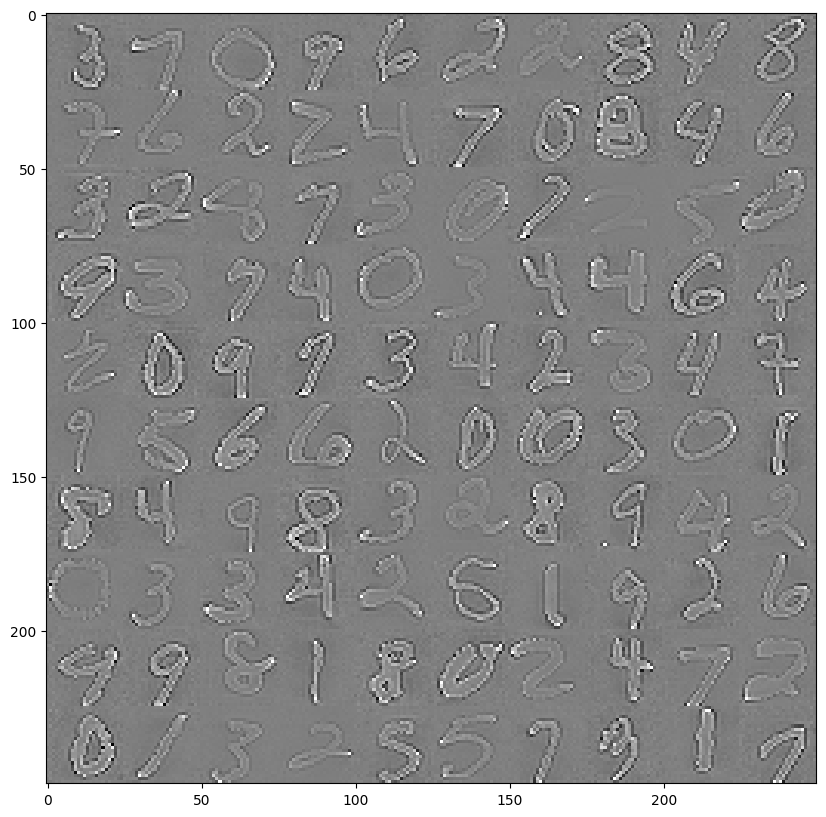

In [26]:

# TODO epsilon
epsilon = 0.1

# TODO perform PCA
pca = PCA(n_components=patch_size * patch_size)
pca.fit(patches)

# Get basis vector components
basis = pca.components_

# Center patches
centered_patches = patches - np.mean(patches, axis=0)

# TODO compute covariance matrix
covariance = np.cov(centered_patches, rowvar=False)

# TODO compute diagonal matrix of standard deviations
eigenvalues = pca.explained_variance_

std_deviations = np.diag(
    1.0 / np.sqrt(eigenvalues + epsilon)
)

# TODO PCA whitening
xPCAwhite = centered_patches @ basis.T @ std_deviations

# TODO ZCA whitening
xZCAwhite = xPCAwhite @ basis

# TODO visualize whitened data
show_in_grid(
    xZCAwhite[:n_basis],
    patch_size,
    patch_size
)


## Exercise 1.2: Comprehension Questions

Answer the following comprehension questions either with *right* or *wrong* and briefly explain your decision:
1. Regardless of the used method for representation learning (i.e. PCA, ICA, SC), the resulting set of basis vectors depends on the given dataset.

right [All three methods learn their basis vectors from the data. Different datasets generally lead to different learned representations.]

2. The first principal component has the smallest eigenvalue and covers the largest possible variance of the data.

Wrong [The first principal component corresponds to the largest eigenvalue, not the smallest. It captures the maximum possible variance.]

3. The optimal number of principal components to retain is 42.

wrong[There is no universally optimal number. It depends on explained variance, reconstruction quality and the application.]

4. After whitening, the features of an observation are uncorrelated and have unit variance.

Right==>>>Ideal full-rank whitening produces uncorrelated features with unit variance. Regularized whitening may give approximate unit variance.

5. The resulting basis vectors of the ICA (i.e. the independent components) are mutually orthogonal.

 Wrong [ICA seeks statistical independence of the component coefficients, not orthogonality of the reconstruction basis vectors.]

6. The ICA is an enhancement of the PCA which additionally aims to make the already uncorrelated features statistically independent.

 Right [In the usual PCA-whitening-based ICA pipeline, ICA goes beyond decorrelation and seeks statistically independent components.]

7. The set of basis vectors of the ICA can be over-complete, i.e. more basis vectors than dimensions of the input space.

 Wrong  [Standard ICA, including sklearn FastICA, does not learn more independent components than input dimensions. Overcomplete ICA variants exist, but are not the standard method used here.]

8. Sparsity means that only a few basis vectors are used to reconstruct an image.

Right [Sparse coding represents each observation with only a small number of nonzero coefficients, so only a few dictionary atoms contribute.]

9. The optimization problem for SC (c.f. equation 1.9 in the lecture notes) is convex.

Wrong ===>>  Jointly optimizing the dictionary and sparse coefficients is generally non-convex. With a fixed dictionary, the usual L1-regularized coefficient problem is convex.

10. Unlike PCA and ICA, SC results in a linear transform of the data.

Wrong [PCA and standard ICA use linear transformations. Sparse coding coefficients are found by sparse optimization and generally do not define a fixed linear transform.]